# 09. Municípios atípicos (P3)

**Pergunta 3:** quais municípios têm incidência atípica em relação ao seu estado, considerando o porte populacional?

| Entrada | Saída |
|---|---|
| `notificacao_dengue_ne`, `populacao_municipio_ano`, `municipio` (tratadas) | classificação de cada município (acima, abaixo ou dentro do esperado), gráficos de funil e listas; achados no fim |

**Por que não ranquear a incidência bruta.** Em município pequeno, poucos casos mudam muito a taxa: os maiores e os
menores valores são quase sempre de municípios pequenos, por acaso. O método compara cada município com o seu estado e
leva em conta o tamanho (gráfico de funil com superdispersão aditiva, Spiegelhalter 2005):
1. período inteiro (2000–2025): casos prováveis e pessoas-ano (soma da população dos anos);
2. **casos esperados (E)** = pessoas-ano × incidência do estado no período; **O/E** = observados ÷ esperados;
3. a variação por acaso de log(O/E) é cerca de 1/E (grande em município pequeno, pequena em município grande);
4. além do acaso, municípios diferem de verdade entre si (surtos locais, vigilância). Essa variação real, **τ²**, é
   estimada em cada estado e somada: o escore é z = log(O/E) ÷ √(1/E + τ²);
5. **atípico** quando |z| > 3,09 (fora de 99,8% do esperado) e **em alerta** quando |z| > 1,96 (fora de 95%), acima ou
   abaixo do estado.

O gráfico de funil mostra isso. Os limites se abririam para municípios pequenos se o acaso dominasse; com 26 anos
somados, até municípios pequenos têm casos esperados suficientes, e o que define a largura é a variação real τ.

**Neste notebook**
1. Dados e cálculo
2. Gráfico de funil por estado
3. Onde estão os atípicos (porte e estado)
4. Municípios acima do esperado
5. Municípios abaixo do esperado
6. Sensibilidade da classificação
7. Achados

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.append(str(RAIZ / "src"))

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import eda

eda.estilo()

## 1. Dados e cálculo

In [2]:
Z_ALERTA, Z_ATIPICO = 1.96, 3.09
painel = eda.painel_municipio_ano()

mun = (painel.groupby(["uf", "cod_mun7", "nome"], observed=True)
             .agg(casos=("provaveis", "sum"), pessoas_ano=("populacao", "sum"), anos=("ano", "nunique"))
             .reset_index())
mun["pop_media"] = mun.pessoas_ano / mun.anos
mun["inc_media"] = eda.incidencia(mun.casos, mun.pessoas_ano)           # casos por 100 mil hab. por ano

taxa_uf = painel.groupby("uf", observed=True).provaveis.sum() / painel.groupby("uf", observed=True).populacao.sum()
mun["esperado"] = mun.pessoas_ano * mun.uf.map(taxa_uf).astype(float)
mun["o_e"] = mun.casos / mun.esperado
mun["log_oe"] = np.log((mun.casos + 0.5) / mun.esperado)


def tau2(d, corte=0.10):
    """Variação real entre municípios (τ²), com z winsorizado nas duas caudas para não depender dos extremos."""
    z = d.log_oe * np.sqrt(d.esperado)
    z = z.clip(z.quantile(corte), z.quantile(1 - corte))
    n, w = len(d), d.esperado
    return max(0.0, (n * (z ** 2).mean() - (n - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))


tau = mun.groupby("uf", observed=True)[["log_oe", "esperado"]].apply(tau2)
mun["z"] = mun.log_oe / np.sqrt(1 / mun.esperado + mun.uf.map(tau).astype(float))
mun["classe"] = np.select(
    [mun.z > Z_ATIPICO, mun.z > Z_ALERTA, mun.z < -Z_ATIPICO, mun.z < -Z_ALERTA],
    ["atípico acima", "alerta acima", "atípico abaixo", "alerta abaixo"], "dentro")
CLASSES = ["atípico acima", "alerta acima", "dentro", "alerta abaixo", "atípico abaixo"]

PORTES = [0, 5_000, 10_000, 20_000, 50_000, 100_000, np.inf]
ROTULOS = ["< 5 mil", "5–10 mil", "10–20 mil", "20–50 mil", "50–100 mil", "> 100 mil"]
mun["porte"] = pd.cut(mun.pop_media, PORTES, labels=ROTULOS, right=False)

# Quanto dos casos do município veio do seu pior ano (alto = atípico por causa de um surto só)
maior_ano = painel.groupby("cod_mun7").provaveis.max()
mun["% no maior ano"] = mun.cod_mun7.map(maior_ano) / mun.casos.where(mun.casos > 0) * 100

print(f"{len(mun):,} municípios; casos {mun.casos.sum():,}")
print(pd.DataFrame({"incidência do estado (por 100 mil/ano)": taxa_uf * 1e5, "τ (desvio entre municípios)": np.sqrt(tau)})
        .loc[eda.UFS].round(2))
print()
print(mun.classe.value_counts().reindex(CLASSES).to_string())

1,794 municípios; casos 4,178,450
    incidência do estado (por 100 mil/ano)  τ (desvio entre municípios)
uf                                                                     
MA                                   98.39                         0.70
PI                                  245.48                         0.65
CE                                  334.06                         0.56
RN                                  577.12                         0.42
PB                                  298.89                         0.49
PE                                  286.71                         0.42
AL                                  377.58                         0.64
SE                                  178.95                         0.42
BA                                  322.21                         0.52

classe
atípico acima        1
alerta acima        37
dentro            1463
alerta abaixo      213
atípico abaixo      80


### Cobertura e reconciliação
A auditoria parte de todos os municípios do cadastro atual do Nordeste e de todos os anos do período. A grade inclui também os anos anteriores à disponibilidade de população de alguns municípios. População ausente ou não positiva impede o cálculo da incidência naquele par.


In [3]:
from config import ANO_INICIO, ANO_FIM

cobertura = eda.consulta("""
    WITH casos AS (
        SELECT cod_mun7, ano, count(*) AS notificacoes,
               count(*) FILTER (WHERE caso_provavel) AS provaveis,
               count(*) FILTER (WHERE caso_provavel AND NOT possivel_duplicata) AS provaveis_sem_dup,
               count(*) FILTER (WHERE caso_confirmado) AS confirmados
        FROM notificacao_dengue_ne
        WHERE ano BETWEEN %(ini)s AND %(fim)s
        GROUP BY cod_mun7, ano
    ), grade AS (
        SELECT m.cod_mun7, m.nome, m.uf_cod, anos.ano
        FROM municipio m
        CROSS JOIN generate_series(%(ini)s::int, %(fim)s::int) AS anos(ano)
        WHERE m.uf_cod = ANY(%(ufs)s)
    )
    SELECT cod_mun7, ano, g.nome, g.uf_cod, p.fonte, p.populacao,
           coalesce(c.notificacoes, 0) AS notificacoes, coalesce(c.provaveis, 0) AS provaveis,
           coalesce(c.provaveis_sem_dup, 0) AS provaveis_sem_dup,
           coalesce(c.confirmados, 0) AS confirmados
    FROM grade g
    FULL JOIN casos c USING (cod_mun7, ano)
    LEFT JOIN populacao_municipio_ano p USING (cod_mun7, ano)
""", {"ini": ANO_INICIO, "fim": ANO_FIM, "ufs": list(eda.UF_SIGLA)})

chave = ["cod_mun7", "ano"]
assert not cobertura.duplicated(chave).any(), "Junção multiplicou chaves de município-ano"
assert cobertura.uf_cod.notna().all(), "Há notificações fora da grade de municípios do Nordeste"
sem_pop = cobertura.loc[~cobertura.populacao.gt(0)]
sem_pop_com_casos = sem_pop.loc[sem_pop.notificacoes.gt(0)]

medidas = ["provaveis", "provaveis_sem_dup", "confirmados"]
com_pop = cobertura.loc[cobertura.populacao.gt(0)]
colunas = ["populacao", *medidas]
pd.testing.assert_frame_equal(
    painel.set_index(chave)[colunas].sort_index(),
    com_pop.set_index(chave)[colunas].sort_index(),
    check_dtype=False,
)
reconciliacao = pd.DataFrame({
    "antes da junção": cobertura[medidas].sum(),
    "sem população válida": sem_pop[medidas].sum(),
    "no painel": painel[medidas].sum(),
})
assert (reconciliacao["antes da junção"] == reconciliacao["sem população válida"] + reconciliacao["no painel"]).all()

print(f"{len(cobertura):,} pares esperados; {len(com_pop):,} com população válida "
      f"({len(com_pop) / len(cobertura):.3%}); {len(sem_pop):,} sem população válida.")
print(f"Pares sem população e com notificação: {len(sem_pop_com_casos):,} "
      f"({sem_pop_com_casos.notificacoes.sum():,} notificações; {sem_pop_com_casos.provaveis.sum():,} prováveis).")
print(f"Pares com população e sem caso provável: {com_pop.provaveis.eq(0).sum():,}.")
display(reconciliacao)
display(com_pop.fonte.value_counts().rename("pares com população válida").to_frame())
display(sem_pop.assign(uf=sem_pop.uf_cod.map(eda.UF_SIGLA))
               [["uf", "cod_mun7", "nome", "ano", "notificacoes", "provaveis"]]
               .sort_values(["uf", "nome", "ano"]).reset_index(drop=True))

46,644 pares esperados; 46,627 com população válida (99.964%); 17 sem população válida.
Pares sem população e com notificação: 0 (0 notificações; 0 prováveis).
Pares com população e sem caso provável: 8,352.


,antes da junção,sem população válida,no painel
provaveis,4178450,0,4178450
provaveis_sem_dup,4098441,0,4098441
confirmados,2884120,0,2884120


,pares com população válida
fonte,
estimativa_6579,37665
interpolada,3587
censo_2000_2010,3581
censo_2022,1794


,uf,cod_mun7,nome,ano,notificacoes,provaveis
0,AL,2703759,Jequiá da Praia,2000,0,0
1,BA,2903276,Barrocas,2000,0,0
2,BA,2919553,Luís Eduardo Magalhães,2000,0,0
3,PI,2200954,Aroeiras do Itaim,2000,0,0
4,PI,2200954,Aroeiras do Itaim,2001,0,0
5,PI,2200954,Aroeiras do Itaim,2002,0,0
6,PI,2200954,Aroeiras do Itaim,2003,0,0
7,PI,2206720,Nazária,2000,0,0
8,PI,2206720,Nazária,2001,0,0
9,PI,2206720,Nazária,2002,0,0


τ = 0,5 quer dizer que, mesmo descontado o acaso, é comum um município ter incidência 1,6 vez maior ou menor que a do
seu estado (e^0,5 ≈ 1,6). Por isso só valores muito longe do estado contam como atípicos.

## 2. Gráfico de funil por estado
Cada ponto é um município. Eixo x: população média (log); eixo y: O/E (log; 1 = igual ao estado, 2 = o dobro).
Tracejado = limites de 95%; contínuo = 99,8%. Os limites quase não se abrem para a esquerda: a variação real
entre municípios (τ) pesa mais que o acaso. Os limites usam 26 anos de população; os 7 municípios criados depois de
2000 têm limites um pouco mais largos que os desenhados.

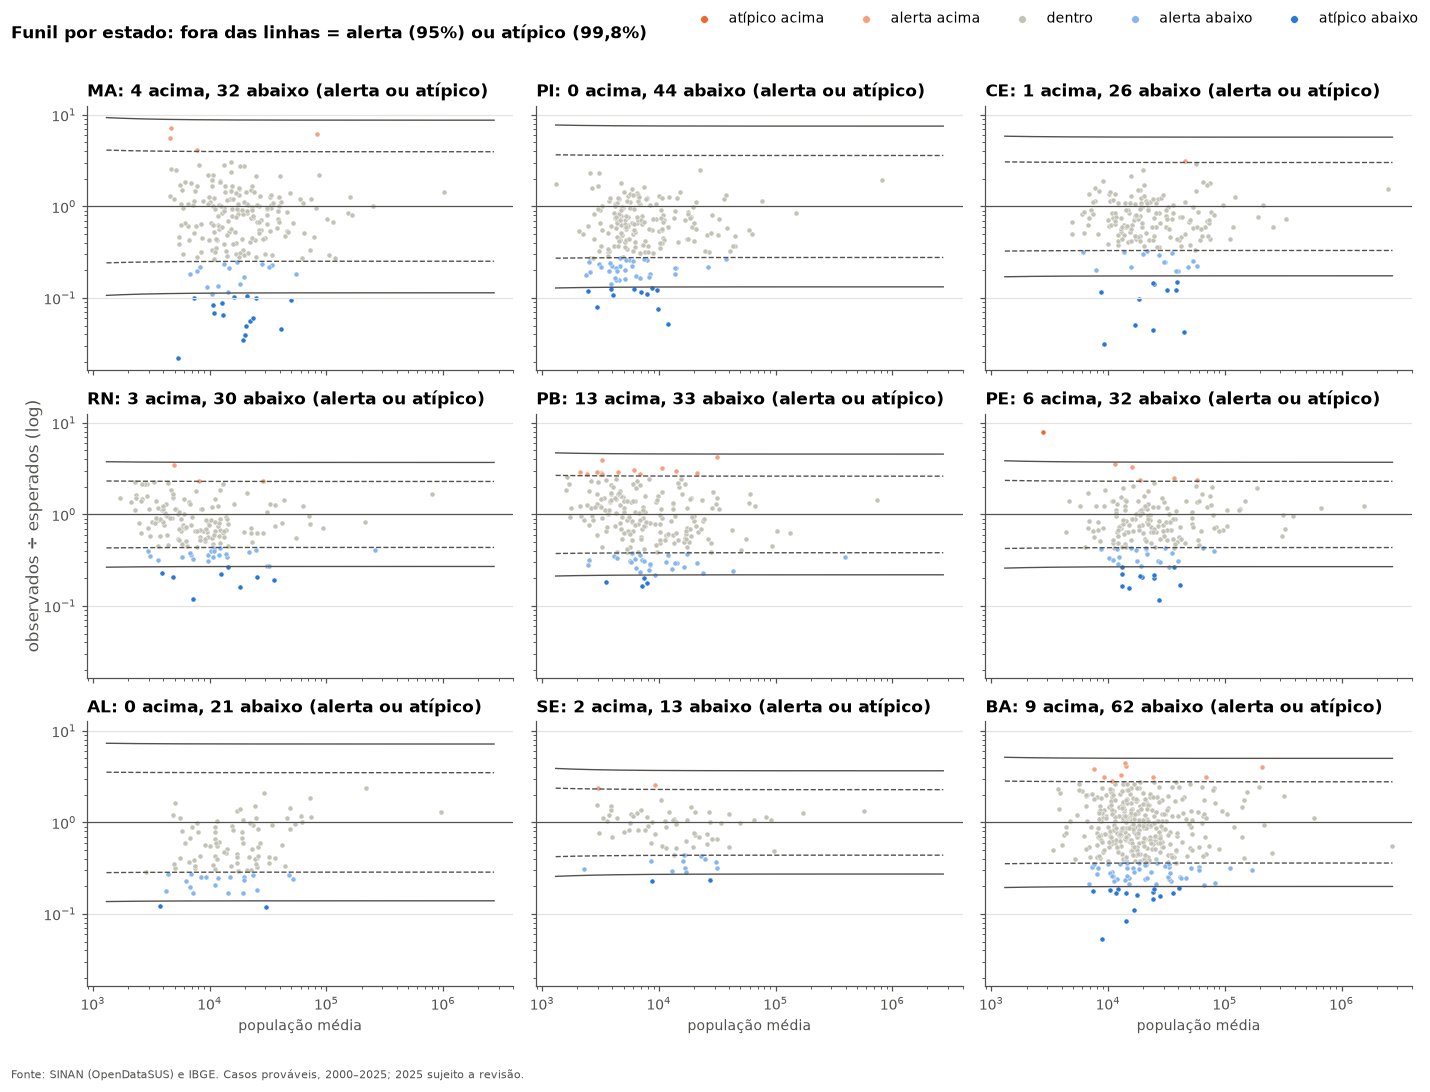

In [4]:
cor = {"atípico acima": eda.COR["comparacao"], "alerta acima": "#f3a27f", "dentro": "#c3c2b7",
       "alerta abaixo": "#86b6ef", "atípico abaixo": eda.COR["principal"]}
fig, axs = plt.subplots(3, 3, figsize=(13, 9.5), sharex=True, sharey=True)
x = np.logspace(np.log10(mun.pop_media.min()), np.log10(mun.pop_media.max()), 200)
for ax, uf in zip(axs.ravel(), eda.UFS):
    d = mun[mun.uf == uf]
    for classe in ["dentro", "alerta acima", "alerta abaixo", "atípico acima", "atípico abaixo"]:
        dd = d[d.classe == classe]
        ax.scatter(dd.pop_media, dd.o_e, s=11, color=cor[classe], label=classe, edgecolor="white", linewidth=0.3)
    esp = x * 26 * taxa_uf[uf]
    dp = np.sqrt(1 / esp + tau[uf])
    for z, estilo in [(Z_ALERTA, "--"), (Z_ATIPICO, "-")]:
        for sinal in (1, -1):
            ax.plot(x, np.exp(sinal * z * dp), ls=estilo, lw=0.9, color=eda.COR["limiar"])
    ax.axhline(1, lw=0.8, color=eda.COR["texto2"])
    n_cima = d.classe.str.endswith("acima").sum()
    n_baixo = d.classe.str.endswith("abaixo").sum()
    ax.set_title(f"{uf}: {n_cima} acima, {n_baixo} abaixo (alerta ou atípico)")
    ax.set_xscale("log")
    ax.set_yscale("log")
handles, labels = axs[0, 0].get_legend_handles_labels()
ordem = [labels.index(c) for c in CLASSES if c in labels]
fig.legend([handles[i] for i in ordem], [labels[i] for i in ordem], loc="upper right", ncol=5, markerscale=1.5)
for ax in axs[-1]:
    ax.set_xlabel("população média")
fig.supylabel("observados ÷ esperados (log)", color=eda.COR["texto2"])
fig.suptitle("Funil por estado: fora das linhas = alerta (95%) ou atípico (99,8%)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
eda.nota(fig)
plt.show()

## 3. Onde estão os atípicos
Por porte (percentual dos municípios de cada porte) e por estado (número de municípios).

In [5]:
por_porte = pd.crosstab(mun.porte, mun.classe, normalize="index").reindex(columns=CLASSES, fill_value=0) * 100
por_porte["municípios"] = mun.porte.value_counts()
por_porte.round(1)

classe,atípico acima,alerta acima,dentro,alerta abaixo,atípico abaixo,municípios
porte,,,,,,
< 5 mil,0.4,4.6,80.8,10.8,3.3,240
5–10 mil,0.0,1.9,79.7,13.8,4.6,369
10–20 mil,0.0,1.5,82.5,11.5,4.5,583
20–50 mil,0.0,1.4,79.4,12.5,6.7,431
50–100 mil,0.0,2.7,87.6,9.7,0.0,113
> 100 mil,0.0,1.7,91.4,6.9,0.0,58


In [6]:
por_uf = pd.crosstab(mun.uf, mun.classe).reindex(columns=CLASSES, fill_value=0)
por_uf["% fora (alerta ou atípico)"] = (1 - por_uf.dentro / por_uf.sum(axis=1)) * 100
por_uf.round(1)

classe,atípico acima,alerta acima,dentro,alerta abaixo,atípico abaixo,% fora (alerta ou atípico)
uf,,,,,,
MA,0,4,181,16,16,16.6
PI,0,0,180,33,11,19.6
CE,0,1,157,15,11,14.7
RN,0,3,134,22,8,19.8
PB,0,13,177,29,4,20.6
PE,1,5,147,21,11,20.5
AL,0,0,81,19,2,20.6
SE,0,2,60,11,2,20.0
BA,0,9,346,47,15,17.0


## 4. Municípios acima do esperado
Os 15 maiores escores (atípicos e em alerta). **% no maior ano** alto indica que o município ficou acima por causa de um surto só, e não por
ter incidência alta de forma persistente.

In [7]:
COLS = ["uf", "nome", "classe", "pop_media", "casos", "esperado", "o_e", "inc_media", "z", "% no maior ano"]
FMT = {"pop_media": "{:,.0f}", "casos": "{:,.0f}", "esperado": "{:,.0f}", "o_e": "{:.2f}",
       "inc_media": "{:,.0f}", "z": "{:.1f}", "% no maior ano": "{:.0f}"}
acima = mun[mun.classe.str.endswith("acima")]
print(f"{len(acima)} municípios acima (alerta ou atípico); população média mediana {acima.pop_media.median():,.0f}; "
      f"% dos casos no maior ano (mediana) {acima['% no maior ano'].median():.0f}%")
acima.sort_values("z", ascending=False)[COLS].head(15).style.format(FMT).hide(axis="index")

38 municípios acima (alerta ou atípico); população média mediana 9,980; % dos casos no maior ano (mediana) 29%


uf,nome,classe,pop_media,casos,esperado,o_e,inc_media,z,% no maior ano
PE,Fernando de Noronha,atípico acima,"2,774","1,630",207,7.88,"2,260",4.8,21
PE,Poção,alerta acima,"11,345","2,988",846,3.53,"1,013",3.0,27
PB,Monteiro,alerta acima,"31,158","10,281","2,421",4.25,"1,269",2.9,30
RN,Rafael Fernandes,alerta acima,"4,944","2,574",742,3.47,"2,002",2.9,25
BA,Uibaí,alerta acima,"13,921","5,151","1,166",4.42,"1,423",2.8,32
PE,Jataúba,alerta acima,"15,937","3,924","1,188",3.30,947,2.8,36
MA,São Pedro dos Crentes,alerta acima,"4,631",848,118,7.16,704,2.8,39
PB,Emas,alerta acima,"3,263",992,254,3.91,"1,169",2.8,26
BA,Barra do Mendes,alerta acima,"14,353","5,030","1,202",4.18,"1,348",2.7,25
BA,Itabuna,alerta acima,"206,882","69,637","17,332",4.02,"1,295",2.7,27


## 5. Municípios abaixo do esperado
Incidência muito abaixo do estado pode ser proteção real ou **subnotificação** (vigilância mais fraca). Os dados não
permitem separar as duas coisas; a lista indica onde olhar.

In [8]:
abaixo = mun[mun.classe.str.endswith("abaixo")]
sem_caso = (mun.casos == 0).sum()
print(f"{len(abaixo)} municípios abaixo (alerta ou atípico), {(mun.classe == 'atípico abaixo').sum()} atípicos; população média mediana {abaixo.pop_media.median():,.0f}; "
      f"{sem_caso} municípios sem nenhum caso provável em 26 anos")
abaixo.sort_values("z")[COLS].head(15).style.format(FMT).hide(axis="index")

293 municípios abaixo (alerta ou atípico), 80 atípicos; população média mediana 13,858; 0 municípios sem nenhum caso provável em 26 anos


uf,nome,classe,pop_media,casos,esperado,o_e,inc_media,z,% no maior ano
CE,Deputado Irapuan Pinheiro,atípico abaixo,"9,132",25,793,0.03,11,-6.1,20
BA,Aratuípe,atípico abaixo,"8,802",39,737,0.05,17,-5.6,18
CE,São Benedito,atípico abaixo,"45,120",167,"3,919",0.04,14,-5.6,14
CE,Ibiapina,atípico abaixo,"24,048",94,"2,089",0.05,15,-5.5,15
CE,Carnaubal,atípico abaixo,"16,904",74,"1,468",0.05,17,-5.3,27
MA,Bacurituba,atípico abaixo,"5,317",3,136,0.02,2,-5.2,33
PE,Trindade,atípico abaixo,"27,417",237,"2,044",0.12,33,-5.1,20
RN,Itajá,atípico abaixo,"7,154",128,"1,073",0.12,69,-5.0,19
MA,Palmeirândia,atípico abaixo,"19,187",17,491,0.03,3,-4.7,41
BA,Jiquiriçá,atípico abaixo,"14,361",102,"1,203",0.08,27,-4.7,35


## 6. Sensibilidade da classificação

Cada cenário altera uma escolha em relação ao modelo principal. Os cortes 5%, 10% e 15% são aplicados a cada cauda na estimativa de τ². Ao excluir possíveis duplicatas, recalculamos as taxas de referência estaduais e τ². O cenário com τ² igual a zero mostra a diferença ao usar somente o componente de variância 1/E. A tabela compara a classificação de atípico acima, atípico abaixo ou não atípico. Alertas entram na última categoria nesta comparação.

In [9]:
# Para cada cenário, recalcular a dispersão estadual quando a entrada muda.
def escore_sensibilidade(casos, esperado, corte):
    base = mun[["uf"]].assign(esperado=esperado, log_oe=np.log((casos + 0.5) / esperado))
    variancia = base.groupby("uf", observed=True)[["log_oe", "esperado"]].apply(tau2, corte=corte)
    return base.log_oe / np.sqrt(1 / esperado + base.uf.map(variancia).astype(float))


sem_dup = painel.groupby("cod_mun7").provaveis_sem_dup.sum()
casos_sem_dup = mun.cod_mun7.map(sem_dup)
taxa_sem_dup = (
    painel.groupby("uf", observed=True).provaveis_sem_dup.sum()
    / painel.groupby("uf", observed=True).populacao.sum()
)
esperado_sem_dup = mun.pessoas_ano * mun.uf.map(taxa_sem_dup).astype(float)

cenarios = {
    "Principal (3,09 / 10%)": (mun.z, Z_ATIPICO),
    "Limiar 2,58": (mun.z, 2.58),
    "Limiar 3,29": (mun.z, 3.29),
    "Winsorização 5%": (escore_sensibilidade(mun.casos, mun.esperado, 0.05), Z_ATIPICO),
    "Winsorização 15%": (escore_sensibilidade(mun.casos, mun.esperado, 0.15), Z_ATIPICO),
    "Sem possíveis duplicatas": (escore_sensibilidade(casos_sem_dup, esperado_sem_dup, 0.10), Z_ATIPICO),
    "Sem dispersão adicional (τ² = 0)": (mun.log_oe * np.sqrt(mun.esperado), Z_ATIPICO),
}

direcao_principal = np.select([mun.z > Z_ATIPICO, mun.z < -Z_ATIPICO], [1, -1], default=0)
principal = direcao_principal != 0
linhas = []
for nome, (escore, limite) in cenarios.items():
    direcao = np.select([escore > limite, escore < -limite], [1, -1], default=0)
    atipico = direcao != 0
    linhas.append({
        "cenário": nome,
        "acima": (direcao == 1).sum(),
        "abaixo": (direcao == -1).sum(),
        "retidos no mesmo lado": (principal & (direcao == direcao_principal)).sum(),
        "novos atípicos": (~principal & atipico).sum(),
        "deixaram de ser atípicos": (principal & ~atipico).sum(),
        "mudaram de lado": (principal & atipico & (direcao != direcao_principal)).sum(),
    })
sensibilidade = pd.DataFrame(linhas).set_index("cenário")
sensibilidade

,acima,abaixo,retidos no mesmo lado,novos atípicos,deixaram de ser atípicos,mudaram de lado
cenário,,,,,,
"Principal (3,09 / 10%)",1,80,81,0,0,0
"Limiar 2,58",11,151,81,81,0,0
"Limiar 3,29",1,60,61,0,20,0
Winsorização 5%,1,46,47,0,34,0
Winsorização 15%,9,117,81,45,0,0
Sem possíveis duplicatas,1,82,81,2,0,0
Sem dispersão adicional (τ² = 0),498,1097,81,1514,0,0


## 7. Achados
- **Variação real grande:** mesmo descontado o acaso, os municípios variam bastante dentro do estado (τ de 0,42 em RN,
  PE e SE a 0,70 no MA). Por isso poucos ficam fora dos limites.
- **Acima do esperado:** 1 município atípico (Fernando de Noronha/PE, O/E 7,9) e 37 em alerta, quase todos pequenos
  (mediana de 10 mil habitantes), mais concentrados na PB (13) e na BA (9). Entre os maiores estão Itabuna/BA (207 mil
  hab., O/E 4,0) e Barra do Corda/MA (83 mil, O/E 6,1). Em mediana, 29% dos casos deles vêm do pior ano: a
  incidência é alta em vários anos, não só num surto.
- **Abaixo do esperado:** 80 atípicos e 213 em alerta, todos com menos de 50 mil habitantes entre os atípicos. Os
  extremos têm pouquíssimos casos para o tamanho (ex.: Deputado Irapuan Pinheiro/CE, 25 casos em 26 anos contra 793
  esperados). Mais comum no MA (16 atípicos) e na BA (15).
- **Leitura:** os desvios para baixo são muito mais fortes que para cima. É compatível com **subnotificação** em
  municípios pequenos, mas os dados não separam isso de menor transmissão; merece conferência com a vigilância.

In [10]:
from IPython.display import Markdown, display

principal_resumo = sensibilidade.iloc[0]
alternativas = sensibilidade.iloc[1:-1]
sem_dispersao = sensibilidade.iloc[-1]
mantidos = int(alternativas["retidos no mesmo lado"].min())
total_atipicos = int(principal_resumo.acima + principal_resumo.abaixo)
totais = alternativas.acima + alternativas.abaixo
display(Markdown(
    f"Com superdispersão aditiva, os cenários alternativos sinalizaram de **{totais.min()} a {totais.max()}** "
    f"municípios atípicos. Eles retiveram pelo menos **{mantidos} de {total_atipicos}** atípicos da análise principal "
    f"no mesmo lado. Sem dispersão adicional, foram sinalizados **{sem_dispersao.acima + sem_dispersao.abaixo}** "
    f"municípios. A lista principal depende dos limiares e da estimativa de dispersão estadual."
))

Com superdispersão aditiva, os cenários alternativos sinalizaram de **47 a 162** municípios atípicos. Eles retiveram pelo menos **47 de 81** atípicos da análise principal no mesmo lado. Sem dispersão adicional, foram sinalizados **1595** municípios. A lista principal depende dos limiares e da estimativa de dispersão estadual.